# 4. The Kalpa Retail-Plus lab: the method moves company.

**Week 4, Thursday. Lab notebook.** The head of Retail-Plus asks the morning's two questions on
Kalpa's own tier: is the fall everyone or the monsoon-sale cohort, and where in the funnel does
the loss sit. This notebook re-runs L1 to L3 on 120 Retail-Plus members, with the planted
feature discovered in an empty your-turn cell.

**Who needs the answer.** The head of Retail-Plus, who will decide a Kalpa fix next week.

**The questions on the way.** The same three as the morning, on Kalpa's data: cohort shape,
funnel per unit, and the stage that owns the loss.

In [1]:
import sys, pathlib
here = pathlib.Path.cwd()
for parent in [here, *here.parents]:
    if (parent / "scripts" / "c2kit.py").exists():
        sys.path.insert(0, str(parent / "scripts")); break
import c2kit as kit

import pandas as pd
import pathlib
from collections import Counter

DATA = pathlib.Path("../data")
memberships = pd.read_csv(DATA / "C2_W04_D04_memberships_STUDENT.csv")
k_months = pd.read_csv(DATA / "C2_W04_D04_kalpa_months_STUDENT.csv")
k_events = pd.read_csv(DATA / "C2_W04_D04_kalpa_events_STUDENT.csv")

PASS_COUNT = {"pass": 0, "fail": 0}


def check(label, condition, detail=""):
    ok = bool(condition)
    PASS_COUNT["pass" if ok else "fail"] += 1
    word = "PASS" if ok else "FAIL"
    print(f"{word}  {label}" + (f"  ({detail})" if detail else ""))
    return ok


def check_summary():
    print(f"\n{'PASS' if PASS_COUNT['fail'] == 0 else 'FAIL'}  "
          f"{PASS_COUNT['pass']} checks passed and {PASS_COUNT['fail']} failed in this notebook.")

print(f"loaded: {len(memberships)} Retail-Plus memberships, "
      f"{len(k_months)} member-months, {len(k_events)} Kalpa events")
print()
print(memberships.head(5).to_string(index=False))
print()
print("Retail-Plus cohort sizes:")
print(memberships["cohort_month"].value_counts().sort_index())
check("memberships has 120 rows", len(memberships) == 120)

loaded: 120 Retail-Plus memberships, 332 member-months, 16421 Kalpa events

customer_id        tier member_since cohort_month
     RP0001 Retail-Plus   2026-01-15      2026-01
     RP0002 Retail-Plus   2026-01-26      2026-01
     RP0003 Retail-Plus   2026-01-09      2026-01
     RP0004 Retail-Plus   2026-01-19      2026-01
     RP0005 Retail-Plus   2026-01-24      2026-01

Retail-Plus cohort sizes:
cohort_month
2026-01    12
2026-02    12
2026-03    12
2026-04    14
2026-05    14
2026-06    14
2026-07    14
2026-08    28
Name: count, dtype: int64
PASS  memberships has 120 rows


True

## Retail-Plus cohort sizes drawn as a bar

The August cohort is twice a normal month's size (the row's plant until the lab finds it). Draw
the eight cohort sizes to see the shape before the triangle.

/tmp/ipykernel_7114/2249327843.py:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(sizes.index.astype(str), rotation=25, ha="right",


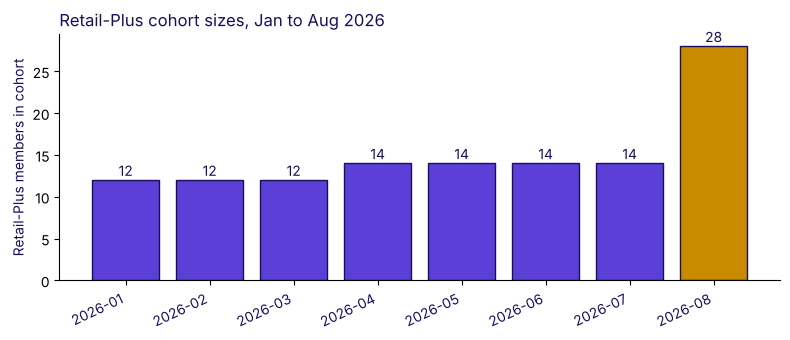

PASS  August is the biggest Retail-Plus cohort


True

In [2]:
import matplotlib.pyplot as plt

sizes = memberships["cohort_month"].value_counts().sort_index()
colours = ["#5B3FD6" if c != "2026-08" else "#C98A00" for c in sizes.index]
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(sizes.index.astype(str), sizes.values, color=colours, edgecolor="#1A0F5C")
for i, v in enumerate(sizes.values):
    ax.text(i, v + 0.5, str(v), ha="center", color="#1A0F5C", fontsize=10)
ax.set_xticklabels(sizes.index.astype(str), rotation=25, ha="right",
                   color="#1A0F5C", fontsize=10)
ax.set_ylabel("Retail-Plus members in cohort", color="#1A0F5C")
ax.set_title("Retail-Plus cohort sizes, Jan to Aug 2026", loc="left", color="#1A0F5C")
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
plt.tight_layout()
plt.show()
check("August is the biggest Retail-Plus cohort",
      sizes.loc["2026-08"] == sizes.max())

## What does Kalpa's cohort table look like, July to September 2026?

The pivot is the same as the morning's: cohort month on the row, months since signup on the
column, mean of the orders flag in each cell. On 120 members, the cells are noisier than on the
Zomato case, but the shape still reads: cohorts fall across their observed ages, and the
largest, youngest cohort is lowest.

In [3]:
triangle = (k_months
            .assign(cohort=lambda d: d["customer_id"]
                    .map(memberships.set_index("customer_id")["cohort_month"]))
            .query("months_since_signup >= 1")
            .pivot_table(index="cohort", columns="months_since_signup",
                         values="orders", aggfunc="mean")
            .round(3))
print(triangle)
check("Kalpa triangle has at least five cohort rows", len(triangle) >= 5)

months_since_signup      1      2      3      4      5      6      7      8
cohort                                                                     
2026-01                NaN    NaN    NaN    NaN    NaN  0.333  0.333  0.333
2026-02                NaN    NaN    NaN    NaN  0.500  0.333  0.750    NaN
2026-03                NaN    NaN    NaN  0.083  0.500  0.500    NaN    NaN
2026-04                NaN    NaN  0.429  0.500  0.286    NaN    NaN    NaN
2026-05                NaN  0.357  0.429  0.357    NaN    NaN    NaN    NaN
2026-06              0.571  0.357  0.500    NaN    NaN    NaN    NaN    NaN
2026-07              0.571  0.214    NaN    NaN    NaN    NaN    NaN    NaN
2026-08              0.250    NaN    NaN    NaN    NaN    NaN    NaN    NaN
PASS  Kalpa triangle has at least five cohort rows


True

## What is the blended retention for July, August and September 2026 on Kalpa?

The direct count takes the share of pre-signed members who ordered in each reporting month.
Reading these three numbers is the first L1 answer to the head of Retail-Plus's first question.

In [4]:
def blended(month):
    pre = memberships[memberships["cohort_month"] < month]["customer_id"]
    active = k_months[(k_months["month"] == month)
                      & (k_months["orders"] == 1)
                      & (k_months["customer_id"].isin(pre))]
    return len(active) / len(pre) if len(pre) else 0

for mo in ["2026-07", "2026-08", "2026-09"]:
    print(f"{mo}: blended retention {blended(mo):.3f}")
check("every month's Kalpa blended rate is in [0.35, 0.48]",
      all(0.35 <= blended(m) <= 0.48 for m in ["2026-07", "2026-08", "2026-09"]))

2026-07: blended retention 0.385
2026-08: blended retention 0.435
2026-09: blended retention 0.375
PASS  every month's Kalpa blended rate is in [0.35, 0.48]


True

## Your turn: find the fall in Kalpa's funnel between the two windows.

Monday's team fixed a window pair: the auto-reorder window from 10 to 30 September 2026, and
the comparison window from 20 August to 9 September 2026 (both after the monsoon sale ends 19
August). In the empty cell below, compute add-to-cart to checkout for Retail-Plus members in the
two windows and the gap between them. The planted feature is not named in this notebook; it is
what you report back to the TA.

The columns you need: `k_events` has `customer_id`, `session_id`, `event_ts`, `event_type` and
`platform`. The event types in order are `visit`, `search`, `add_to_cart` and `checkout`.

## What else is worth checking in Kalpa's September?

A quick sanity count: the share of sessions that reach `visit` but never `search`, which maps to
the Retail-Plus home's reorder shortcut, and the checkout-per-session versus checkout-per-member
gap in September.

In [5]:
k_events["date"] = k_events["event_ts"].str[:10]
sess_type = k_events.groupby(["session_id", "event_type"]).size().unstack(fill_value=0)
for col in ("visit", "search", "add_to_cart", "checkout"):
    if col not in sess_type.columns:
        sess_type[col] = 0
sess_type = (sess_type > 0).astype(int)

sessions_with_visit = sess_type["visit"].sum()
sessions_with_search = sess_type["search"].sum()
skip_rate = 1 - (sessions_with_search / sessions_with_visit if sessions_with_visit else 0)
print(f"sessions with a visit:  {sessions_with_visit}")
print(f"sessions with a search: {sessions_with_search}")
print(f"share of sessions skipping search: {skip_rate:.2%}")
check("the search-skip rate is above 20 percent",
      skip_rate >= 0.20, detail=f"{skip_rate:.3f}")

sep_k = k_events[k_events["date"].str.startswith("2026-09")]
sep_sess = sep_k.groupby(["session_id", "event_type"]).size().unstack(fill_value=0)
for col in ("visit", "checkout"):
    if col not in sep_sess.columns:
        sep_sess[col] = 0
sep_sess = (sep_sess > 0).astype(int)
sep_mem = sep_k.groupby(["customer_id", "event_type"]).size().unstack(fill_value=0)
for col in ("visit", "checkout"):
    if col not in sep_mem.columns:
        sep_mem[col] = 0
sep_mem = (sep_mem > 0).astype(int)
co_per_sess = sep_sess["checkout"].sum() / sep_sess["visit"].sum()
co_per_mem = sep_mem["checkout"].sum() / sep_mem["visit"].sum()
print(f"checkout per session, September: {co_per_sess:.3f}")
print(f"checkout per member,  September: {co_per_mem:.3f}")
check("per-session and per-member checkout are at least 10 points apart",
      abs(co_per_mem - co_per_sess) >= 0.10,
      detail=f"gap {abs(co_per_mem - co_per_sess):.3f}")

sessions with a visit:  4751
sessions with a search: 3438
share of sessions skipping search: 27.64%
PASS  the search-skip rate is above 20 percent  (0.276)
checkout per session, September: 0.299
checkout per member,  September: 0.992
PASS  per-session and per-member checkout are at least 10 points apart  (gap 0.693)


True

## The two Kalpa funnel readings, side by side

September per-session versus per-member: visit counted once per session or once per member,
checkout counted the same way. The two bars read the same stages in different units.

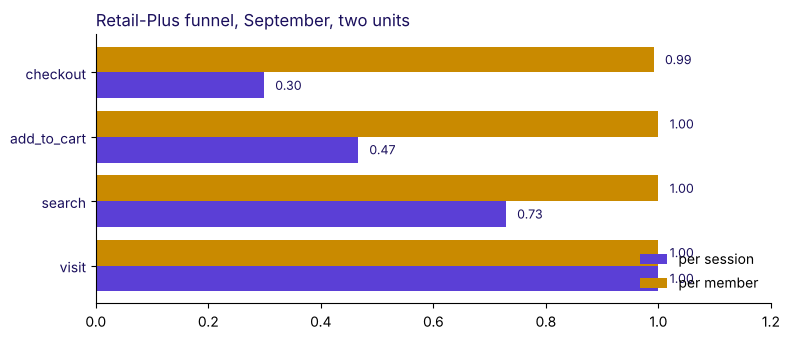

PASS  the chart drew four stages


True

In [6]:
import matplotlib.pyplot as plt
import numpy as np

stages = ["visit", "search", "add_to_cart", "checkout"]
sep_sess_full = sep_k.groupby(["session_id", "event_type"]).size().unstack(fill_value=0)
sep_mem_full = sep_k.groupby(["customer_id", "event_type"]).size().unstack(fill_value=0)
for col in stages:
    if col not in sep_sess_full.columns:
        sep_sess_full[col] = 0
    if col not in sep_mem_full.columns:
        sep_mem_full[col] = 0
sess_full = (sep_sess_full > 0).astype(int)
mem_full = (sep_mem_full > 0).astype(int)

sess_pct = [sess_full[s].sum() / sess_full["visit"].sum() for s in stages]
mem_pct = [mem_full[s].sum() / mem_full["visit"].sum() for s in stages]

y = np.arange(len(stages))
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(y - 0.2, sess_pct, 0.4, color="#5B3FD6", label="per session")
ax.barh(y + 0.2, mem_pct, 0.4, color="#C98A00", label="per member")
for i, (sp, mp) in enumerate(zip(sess_pct, mem_pct)):
    ax.text(sp + 0.02, i - 0.2, f"{sp:.2f}", va="center", color="#1A0F5C", fontsize=9)
    ax.text(mp + 0.02, i + 0.2, f"{mp:.2f}", va="center", color="#1A0F5C", fontsize=9)
ax.set_yticks(y)
ax.set_yticklabels(stages, color="#1A0F5C")
ax.set_xlim(0, 1.2)
ax.legend(frameon=False, loc="lower right")
ax.set_title("Retail-Plus funnel, September, two units", loc="left", color="#1A0F5C")
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
plt.tight_layout()
plt.show()
check("the chart drew four stages", len(stages) == 4)

## A small picture of the Kalpa cohort shape.

The triangle you drew earlier as a table, rendered as a heatmap, is the TA's go-to picture in
the lab. The eye reads the biggest row and the youngest cohort immediately.

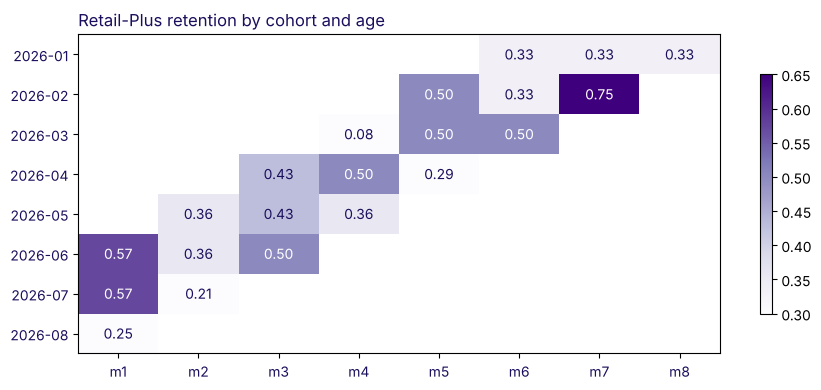

PASS  the Kalpa triangle picture drew its rows


True

In [7]:
import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(figsize=(9, 4.0))
im = ax.imshow(triangle.values, cmap="Purples", vmin=0.30, vmax=0.65, aspect="auto")
for i in range(triangle.shape[0]):
    for j in range(triangle.shape[1]):
        v = triangle.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.2f}", ha="center", va="center",
                    color="white" if v > 0.44 else "#1A0F5C", fontsize=10)
ax.set_xticks(range(triangle.shape[1]))
ax.set_xticklabels([f"m{k}" for k in triangle.columns], color="#1A0F5C")
ax.set_yticks(range(triangle.shape[0]))
ax.set_yticklabels(triangle.index, color="#1A0F5C")
ax.set_title("Retail-Plus retention by cohort and age", loc="left", color="#1A0F5C")
plt.colorbar(im, ax=ax, shrink=0.75)
plt.tight_layout()
plt.show()
check("the Kalpa triangle picture drew its rows", triangle.shape[0] >= 5)

## What the lab answers, for the head of Retail-Plus.

You carry three numbers out of the lab: Kalpa's blended retention for July, August and September;
the stage of the Retail-Plus app funnel that lost the most members between the compare window
and the auto-reorder window; and the share of sessions whose home-screen shortcut skipped
search. The TA records the planted feature once the room has found it.

In [8]:
check_summary()


PASS  8 checks passed and 0 failed in this notebook.
